# COMP 345 midterm demo: TF-IDF and a frozen Gemini embedding

This notebook shows the two representations finished for the midterm. Both use the same normalized ingredient text, the same group-aware splits, and the same linear probe. It reads saved files only: no Gemini call, and no training.

Probability fusion and feature fusion are the next experiments. They are not part of this demo.

In [1]:
%matplotlib inline
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "artifacts").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "artifacts" / "midterm"
FAILURE = RESULTS

MIDTERM_METHODS = ("tfidf", "embedding")
METHOD_NAME = {"tfidf": "TF-IDF", "embedding": "Gemini embedding"}

result = json.loads((RESULTS / "results.json").read_text(encoding="utf-8"))
rows = [row for row in result["rows"] if row["method"] in MIDTERM_METHODS]
print("Project root:", ROOT)
print("Labelled recipes:", result["dataset_summary"]["recipes"])
print("Ingredient groups:", result["dataset_summary"]["groups"])
print("Ambiguous groups / recipes:", result["dataset_summary"]["ambiguous_groups"], "/", result["dataset_summary"]["ambiguous_recipes"])
print("Classes:", len(result["label_space"]))
print("Methods in this demo:", ", ".join(METHOD_NAME[name] for name in MIDTERM_METHODS))
print("Evaluation rows:", len(rows))

Project root: E:\Rice_Fall2026\COMP345\TermProject
Labelled recipes: 39774
Ingredient groups: 39242
Ambiguous groups / recipes: 14 / 30
Classes: 20
Methods in this demo: TF-IDF, Gemini embedding
Evaluation rows: 48


## Input

One labelled recipe from `data/whats-cooking/train.json`. The model sees the ingredient list and predicts the cuisine. The unlabeled Kaggle test file is not used.

In [2]:
train_path = ROOT / "data" / "whats-cooking" / "train.json"
if train_path.exists():
    with train_path.open(encoding="utf-8") as handle:
        first_recipe = json.load(handle)[0]
    print("File:", train_path.name)
    print(json.dumps(first_recipe, indent=2))
else:
    print("data/whats-cooking/train.json not found; download it from Kaggle (see README).")


File:

 train.json
{
  "id": 10259,
  "cuisine": "greek",
  "ingredients": [
    "romaine lettuce",
    "black olives",
    "grape tomatoes",
    "garlic",
    "pepper",
    "purple onion",
    "seasoning",
    "garbanzo beans",
    "feta cheese crumbles"
  ]
}


## Setup that is already frozen

Ingredients are lowercased, trimmed, sorted, and joined with newlines. Identical normalized lists stay in the same split. The outer evaluation is three stratified group-aware folds. Inside each development pool, about 15% is validation. The learning curve uses 2, 5, 10, 20, 40, 60, 80, and 100% of the training pool. The seed is 345.

TF-IDF is fit on the current training subset only. Validation chooses word unigrams, word unigrams plus bigrams, or whole-ingredient tokens. The Gemini cache is `gemini-embedding-001`, task type `CLASSIFICATION`, 768 dimensions. The probe is a PyTorch linear softmax trained with cross-entropy.

In [3]:
plan = result["split_plan"]
print("Seed:", plan["seed"])
print("Outer folds:", len(plan["folds"]))
print("Validation fraction:", plan["validation_fraction"])
print("Training proportions:", plan["proportions"])
for fold in plan["folds"]:
    print(
        f"fold {fold['fold']}: "
        f"train {len(fold['train_pool']):,} | "
        f"validation {len(fold['validation']):,} | "
        f"test {len(fold['test']):,}"
    )

cache_path = ROOT / "artifacts" / "gemini-embedding-001.npz"
print()
if cache_path.exists():
    with np.load(cache_path, allow_pickle=False) as cache:
        vectors = cache["vectors"]
        metadata = json.loads(str(cache["metadata"].item()))
    print("Embedding cache:", vectors.shape, vectors.dtype)
    print("Model:", metadata["model"])
    print("Task type:", metadata["task_type"])
    print("Finite values:", bool(np.isfinite(vectors).all()))
else:
    print("Embedding cache not found; the results below are read from artifacts/midterm.")

Seed: 345
Outer folds: 3
Validation fraction: 0.15
Training proportions: [2, 5, 10, 20, 40, 60, 80, 100]
fold 0: train 22,703 | validation 3,801 | test 13,270
fold 1: train 22,731 | validation 3,798 | test 13,245
fold 2: train 22,714 | validation 3,801 | test 13,259



Embedding cache: (39774, 768) float32
Model: gemini-embedding-001
Task type: CLASSIFICATION
Finite values: True


## Full-training comparison

Macro-F1 is the primary metric. Each number is the mean of the three outer test folds at the 100% training proportion. The paired interval resamples complete ingredient groups inside each fold.

In [4]:
order = {name: index for index, name in enumerate(MIDTERM_METHODS)}
summary_100 = [row for row in result["summary"] if row["proportion"] == 100 and row["method"] in order]
summary_100.sort(key=lambda row: order[row["method"]])
for row in summary_100:
    accuracies = [
        item["accuracy"]
        for item in rows
        if item["proportion"] == 100 and item["method"] == row["method"]
    ]
    folds = ", ".join(f"{score:.4f}" for score in row["fold_scores"])
    print(
        f"{METHOD_NAME[row['method']]:18s}  "
        f"macro-F1={row['mean_macro_f1']:.4f} ± {row['std_macro_f1']:.4f}  "
        f"accuracy={float(np.mean(accuracies)):.4f}"
    )
    print(f"{'':18s}  folds: {folds}")

bootstrap = result["primary_bootstrap_embedding_minus_tfidf"]
print()
print("Gemini embedding minus TF-IDF")
print(f"  difference = {bootstrap['difference']:.4f}")
print(f"  95% interval = [{bootstrap['ci_95_low']:.4f}, {bootstrap['ci_95_high']:.4f}]")

TF-IDF              macro-F1=0.7048 ± 0.0053  accuracy=0.7820
                    folds: 0.6987, 0.7080, 0.7076
Gemini embedding    macro-F1=0.6462 ± 0.0135  accuracy=0.7631
                    folds: 0.6397, 0.6372, 0.6617

Gemini embedding minus TF-IDF
  difference = -0.0586
  95% interval = [-0.0652, -0.0523]


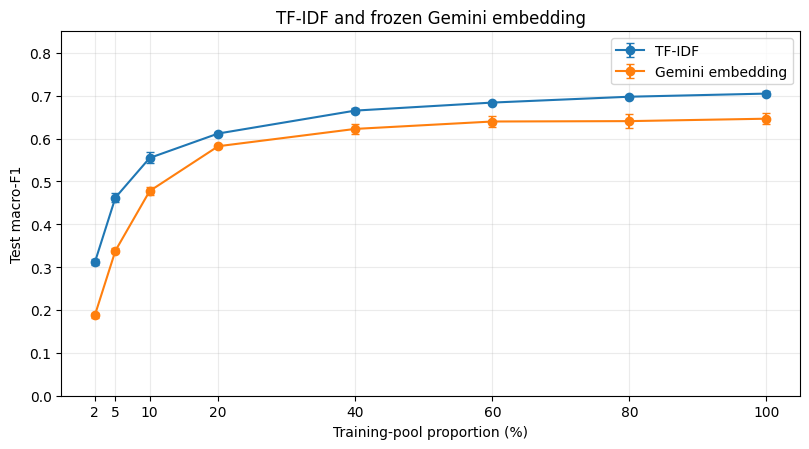

In [5]:
proportions = sorted({int(row["proportion"]) for row in rows})
figure, axis = plt.subplots(figsize=(8.2, 4.6))
for method in MIDTERM_METHODS:
    means = []
    deviations = []
    for proportion in proportions:
        values = [
            float(row["macro_f1"])
            for row in rows
            if row["method"] == method and int(row["proportion"]) == proportion
        ]
        means.append(float(np.mean(values)))
        deviations.append(float(np.std(values, ddof=1)))
    axis.errorbar(proportions, means, yerr=deviations, marker="o", capsize=3, label=METHOD_NAME[method])
axis.set_xlabel("Training-pool proportion (%)")
axis.set_ylabel("Test macro-F1")
axis.set_title("TF-IDF and frozen Gemini embedding")
axis.set_xticks(proportions)
axis.set_ylim(0, 0.85)
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
plt.show()

TF-IDF is ahead at every training proportion. At 100% the paired interval is entirely below zero, and well below the +0.02 threshold in the hypothesis. On this task the frozen embedding does not replace the lexical baseline.

The gap is wider when the training pool is small: about 0.31 versus 0.19 macro-F1 at 2%, and 0.705 versus 0.646 at 100%.

## Per-class F1

Macro-F1 weights the 20 cuisines equally. Large classes such as Mexican and Italian are high for both methods. The embedding loses the most on smaller or overlapping classes, including Brazilian, Irish, Russian, and British.

In [6]:
per_class = list(csv.DictReader((FAILURE / "per_class_100.csv").open(encoding="utf-8")))
print(f"{'class':16s} {'TF-IDF':>8s} {'Gemini':>8s} {'gap':>8s}")
for label in result["label_space"]:
    scores = {
        item["method"]: float(item["mean_f1"])
        for item in per_class
        if item["class"] == label and item["method"] in MIDTERM_METHODS
    }
    gap = scores["embedding"] - scores["tfidf"]
    print(f"{label:16s} {scores['tfidf']:8.3f} {scores['embedding']:8.3f} {gap:8.3f}")

class              TF-IDF   Gemini      gap
brazilian           0.612    0.393   -0.219
british             0.460    0.346   -0.114
cajun_creole        0.725    0.721   -0.004
chinese             0.817    0.808   -0.009
filipino            0.653    0.585   -0.069
french              0.615    0.586   -0.029
greek               0.750    0.713   -0.037
indian              0.883    0.878   -0.005
irish               0.548    0.427   -0.121
italian             0.843    0.834   -0.010
jamaican            0.768    0.655   -0.113
japanese            0.744    0.735   -0.009
korean              0.790    0.719   -0.071
mexican             0.910    0.909   -0.001
moroccan            0.795    0.759   -0.036
russian             0.489    0.382   -0.107
southern_us         0.745    0.720   -0.025
spanish             0.536    0.456   -0.080
thai                0.779    0.750   -0.029
vietnamese          0.632    0.548   -0.084


## Where the two models disagree

Each labelled recipe is a test recipe in exactly one outer fold. The counts below use the saved 100% predictions for the two completed methods.

In [7]:
def top_confusions(path, limit=5):
    with Path(path).open(encoding="utf-8", newline="") as handle:
        table = list(csv.DictReader(handle))
    labels = [name for name in table[0] if name not in ("method", "true_class")]
    pairs = []
    for row in table:
        for predicted in labels:
            if predicted == row["true_class"]:
                continue
            count = int(row[predicted])
            if count:
                pairs.append((count, row["true_class"], predicted))
    pairs.sort(reverse=True)
    return pairs[:limit]

for method, filename in (("TF-IDF", "confusion_tfidf_100.csv"), ("Gemini embedding", "confusion_embedding_100.csv")):
    print(method)
    for count, true_class, predicted in top_confusions(FAILURE / filename):
        print(f"  {true_class:16s} -> {predicted:16s} {count:,}")
    print()

both_correct = tfidf_only = embedding_only = both_wrong = 0
tfidf_only_cases = []
embedding_only_cases = []
both_wrong_cases = []
with (FAILURE / "error_cases_100.csv").open(encoding="utf-8", newline="") as handle:
    for case in csv.DictReader(handle):
        tfidf_hit = case["tfidf_pred"] == case["true_class"]
        embedding_hit = case["embedding_pred"] == case["true_class"]
        if tfidf_hit and embedding_hit:
            both_correct += 1
        elif tfidf_hit:
            tfidf_only += 1
            tfidf_only_cases.append(case)
        elif embedding_hit:
            embedding_only += 1
            embedding_only_cases.append(case)
        else:
            both_wrong += 1
            both_wrong_cases.append(case)

print(f"{'both correct':22s} {both_correct:,}")
print(f"{'TF-IDF only':22s} {tfidf_only:,}")
print(f"{'Gemini embedding only':22s} {embedding_only:,}")
print(f"{'both wrong':22s} {both_wrong:,}")

def show(title, case):
    print()
    print(title)
    print(
        f"  id={case['recipe_id']}  true={case['true_class']}  "
        f"TF-IDF={case['tfidf_pred']}  Gemini={case['embedding_pred']}"
    )
    print(" ", case["ingredients"][:220])

def first_match(pool, predicate):
    matches = [case for case in pool if predicate(case)]
    return sorted(matches, key=lambda case: int(case["recipe_id"]))[0]

show(
    "TF-IDF keeps a British recipe that the embedding calls Indian",
    first_match(
        tfidf_only_cases,
        lambda case: case["true_class"] == "british" and case["embedding_pred"] == "indian",
    ),
)
show(
    "Gemini keeps a Vietnamese recipe that TF-IDF calls Thai",
    first_match(
        embedding_only_cases,
        lambda case: case["true_class"] == "vietnamese" and case["tfidf_pred"] == "thai",
    ),
)
show(
    "Both models call a French recipe Italian",
    first_match(
        both_wrong_cases,
        lambda case: case["true_class"] == "french" and case["tfidf_pred"] == "italian" and case["embedding_pred"] == "italian",
    ),
)

TF-IDF
  french           -> italian          523
  italian          -> french           339
  cajun_creole     -> southern_us      260
  southern_us      -> italian          205
  greek            -> italian          199

Gemini embedding
  french           -> italian          657
  greek            -> italian          287
  spanish          -> italian          279
  cajun_creole     -> southern_us      276
  italian          -> french           273



both correct           28,326
TF-IDF only            2,779
Gemini embedding only  2,025
both wrong             6,644

TF-IDF keeps a British recipe that the embedding calls Indian
  id=22884  true=british  TF-IDF=british  Gemini=indian
  white vinegar | pearl onions | cucumber | ground ginger | all-purpose flour | ground turmeric | cauliflower | salt | white sugar | water | mustard powder

Gemini keeps a Vietnamese recipe that TF-IDF calls Thai
  id=2145  true=vietnamese  TF-IDF=thai  Gemini=vietnamese
  rice vinegar | lime juice | asian fish sauce | hot chili | sugar | garlic cloves

Both models call a French recipe Italian
  id=8  true=french  TF-IDF=italian  Gemini=italian
  whole milk | fine sea salt | vanilla sugar | lemon | hazelnuts | baking powder | all-purpose flour | large eggs | extra-virgin olive oil


The largest confusions are neighboring cuisines that share ingredients: French and Italian, Cajun Creole and Southern US, Vietnamese and Thai. A better representation cannot recover a distinction that the ingredient list does not contain.

## Where the midterm stops

Done: shared normalization, frozen group-aware splits, the TF-IDF arm, the cached Gemini embedding, the learning curve, and the paired comparison.

Not in this demo: probability fusion and feature fusion. Those are the remaining experiments, to test whether the two representations carry complementary information. The same splits will be reused.